# CA3

### Group 3

Group members:
- Vinicius Millan Santa Catharina
- Zaur Kambiev
- Stig Espen Paulsberg

### Imports

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

### Reading data

In [3]:
# Reading data
df_train = pd.read_csv("train.csv")

### Data exploration and visualisation

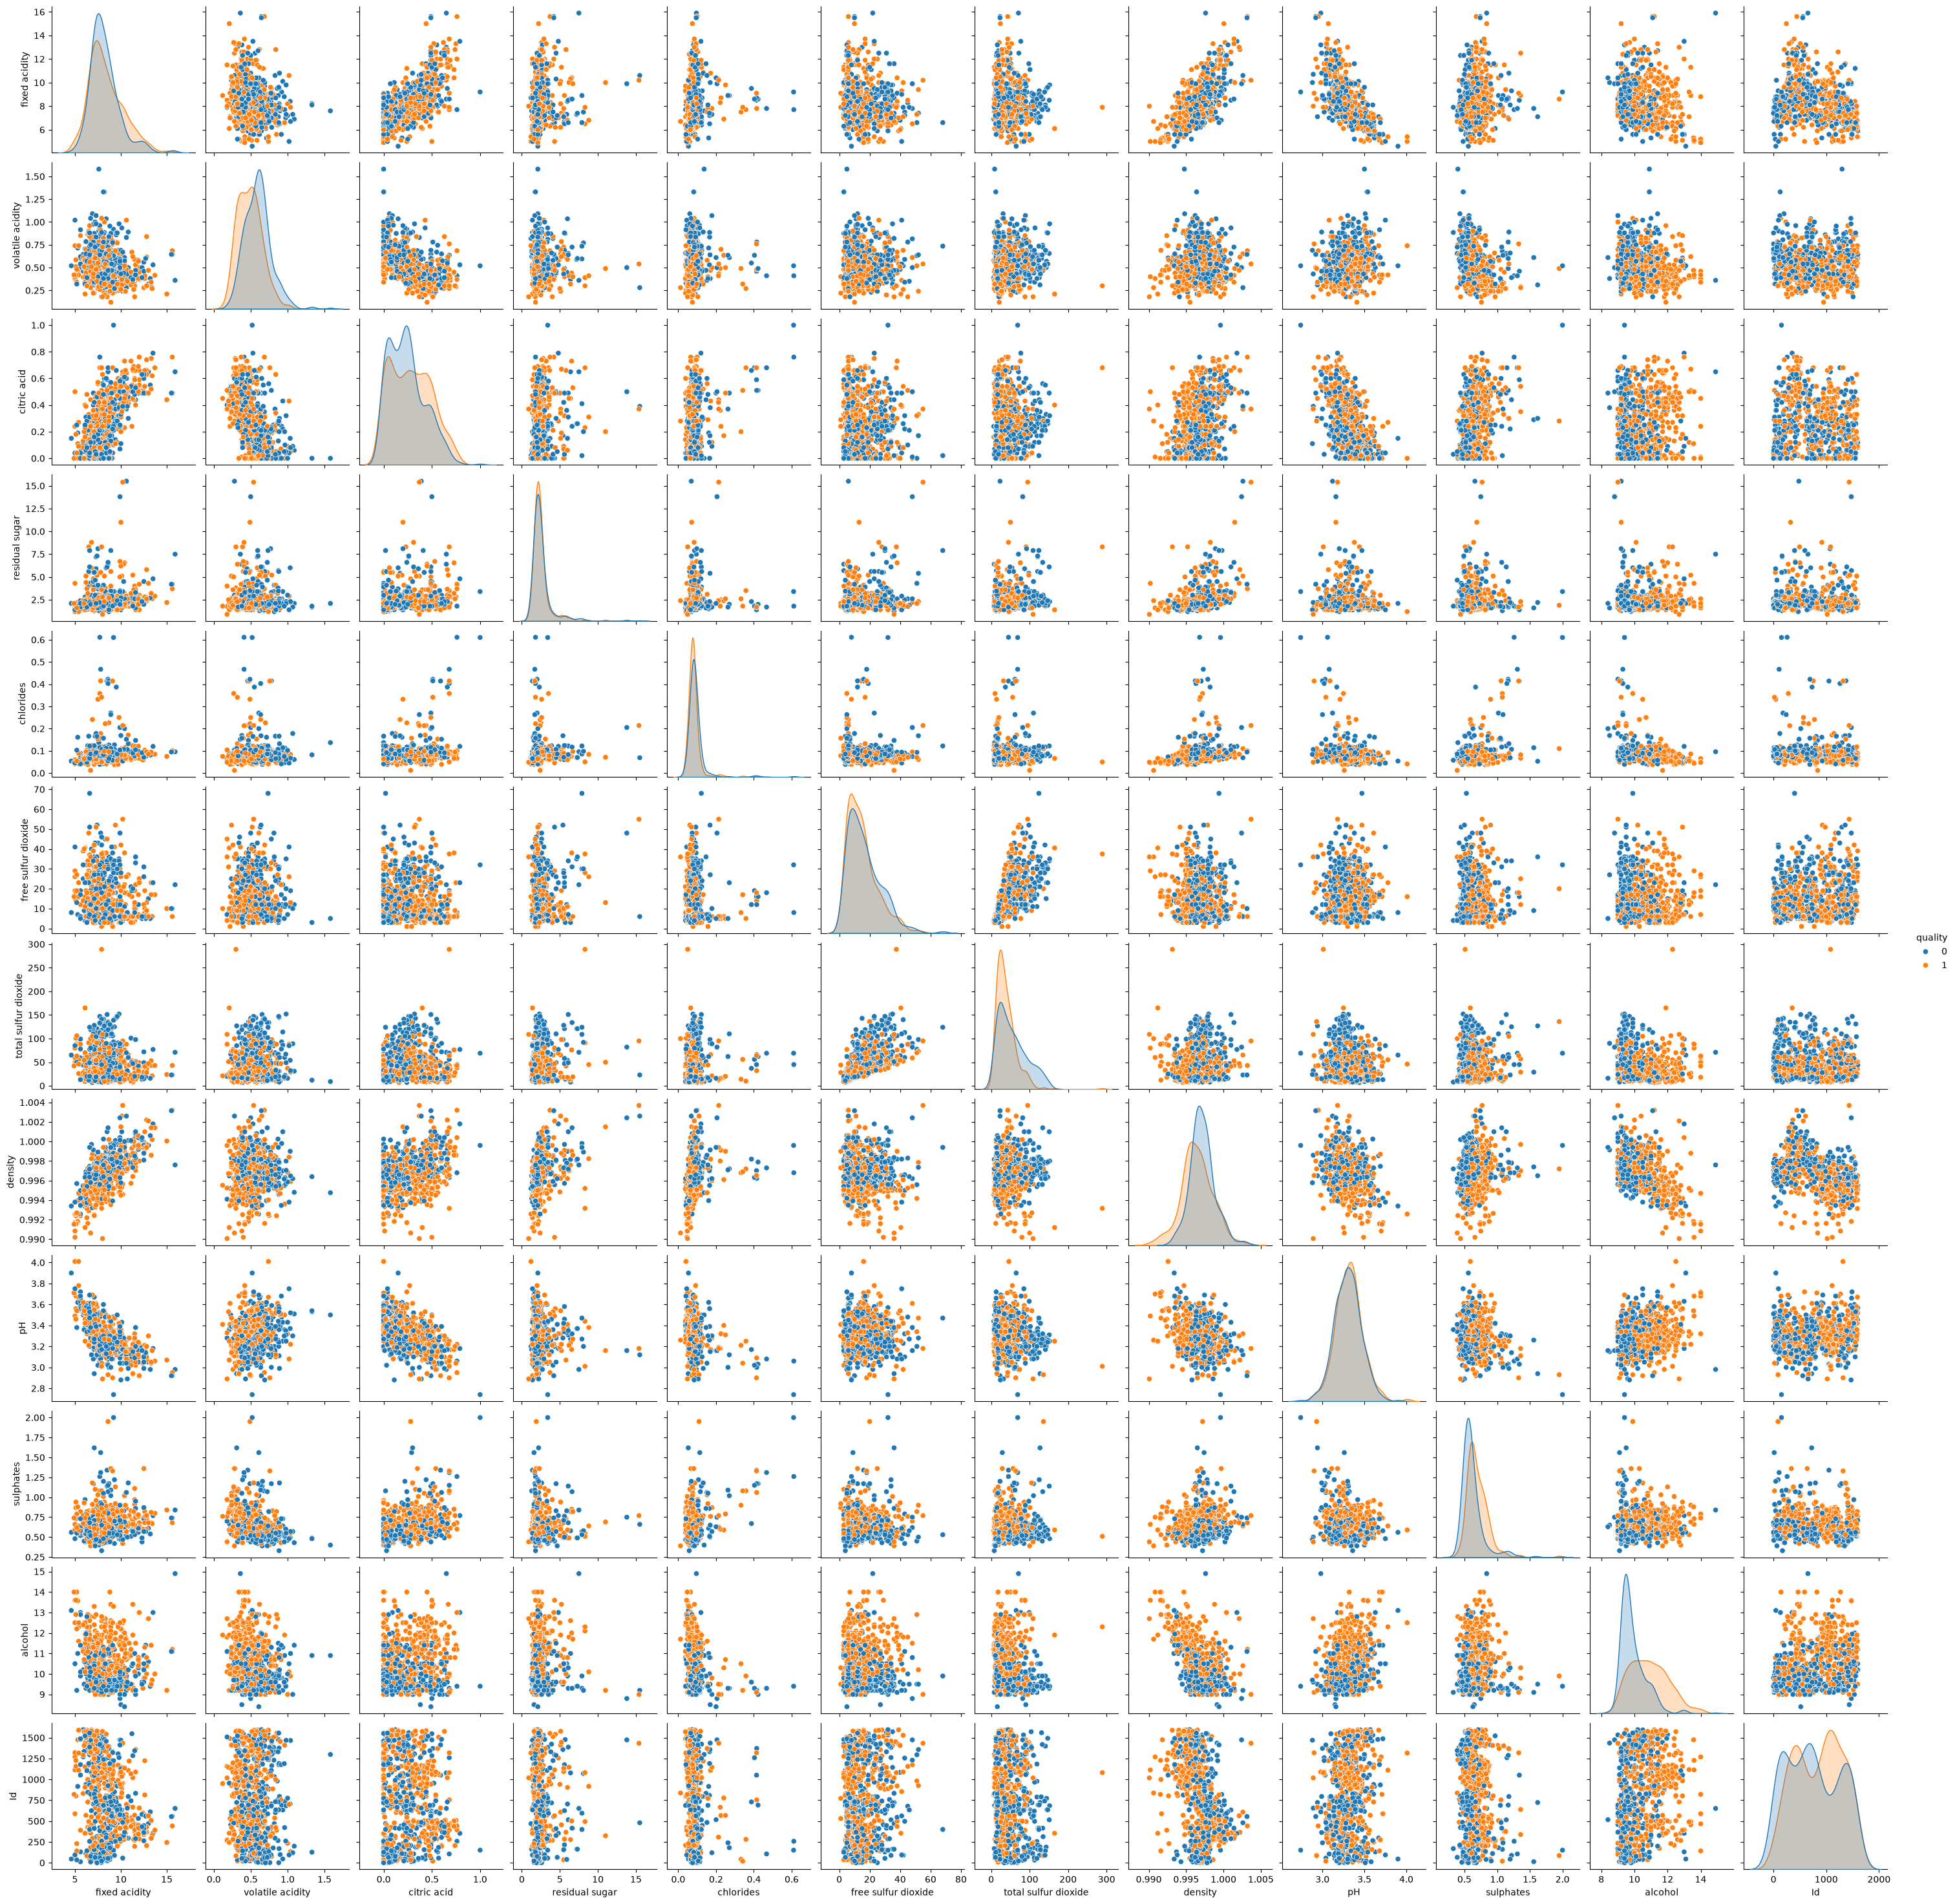

In [4]:
sns.pairplot(
    data=df_train,
    hue='quality'
)
plt.show()

#### Summary

It is difficult to see a clear pattern between features and quality of wine. But we see that there are some differences in distribution between good and bad wine for *alcohol*, *total sulfur dioxide*, *volatile acidity*. We use that as a starting point when building our model.

Correlation heat map

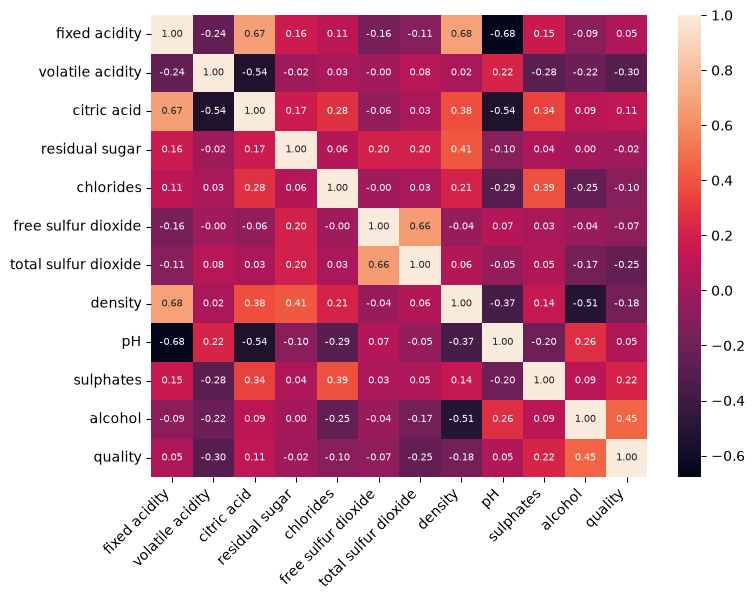

In [5]:
# Correlation between features
df_train_corr = df_train.drop(
    ['Id'],
    axis=1
).corr()

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(
    data=df_train_corr,
    annot=True,
    annot_kws={"size":7},
    fmt=".2f"
)
plt.xticks(
    rotation=45,
    ha='right'
)
plt.show()

#### Summary

We use the heat map to possibly remove some features based on correlation to quality and inbetween the features.

For example *volatile acidity* and *fixed acidity* are highly correlated with each other. We notice that *fixed acidity* has a low correlation with quality compared to *volatile acidity*. Another thing to notice about *fixed acidity* is that is density and pH as well.

*Free sulfur dioxide* and *total sulfur dioxide* are highly correlated with each other as well. *Total sulfur dioxide* has a higher correlation with *quality* than *free sulfur dioxide*.

*Alcohol* is the feature with highest correlation with *quality*.

We took this into account when building our model.

### Box plots

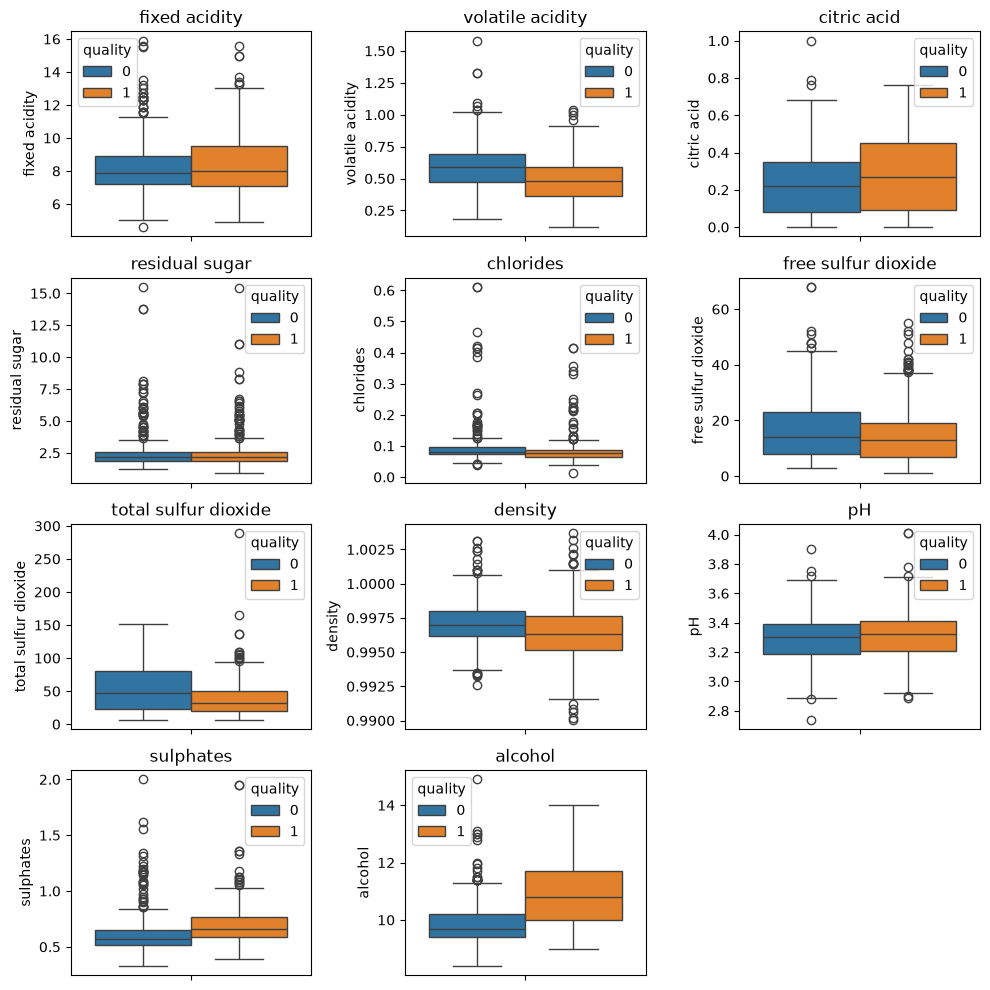

In [6]:
# Features to plot
features = df_train.select_dtypes(include=['number']).columns[:11]

fig, axes = plt.subplots(4, 3, figsize=(10, 10))
axes = axes.ravel()

# plotting for each feature
for i, feature in enumerate(features):
    sns.boxplot(
        data=df_train,
        y=feature,
        ax=axes[i],
        hue='quality'
    )
    axes[i].set_title(feature)
    
# hiding last empty subplot
axes[11].axis('off')

plt.tight_layout()
plt.show()

#### Summary

Looking at the box plots we can see there are outliers in many of the features, but many of the features are also skewed. We believe that choosing a model that is not based on linear methods and distance is a good choice here. We wanted to move on building a Random forest classifier. Regarding outliers, we decided not to remove any because of our choice of model.

### Data cleaning

Look for missing values

In [7]:
df_train.isna().sum() # No missing values

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Look for duplicated values

In [8]:
print(df_train.shape)
df_train.drop(['Id'], axis=1).duplicated().sum() # 75 duplicate
df_train = df_train.drop(['Id'], axis=1).drop_duplicates()
print(df_train.shape)

(835, 13)
(760, 12)


75 observations are removed

### Summary

Based on our analysis we are confident in features like *alcohol, volatile acidity, total sulfur dioxide, sulphates*. We are also moving forward with Random Forest Classifier and we will try to optimize with hyperparameter tuning and feature engineering instead of data processing. 

### Feature engineering

We tried to engineer 3 different features

In [9]:
# Alcohol density
df_train['wine_fraction_density'] =  df_train['density'] - df_train['alcohol']*0.789/100

# Bound sulfur dioxide
df_train['bound sulfur dioxide'] = df_train['total sulfur dioxide'] - df_train['free sulfur dioxide']

# Ratio
df_train['sulfur dioxide ratio'] = df_train['free sulfur dioxide'] - df_train['total sulfur dioxide']

/tmp/ipykernel_24933/1895544239.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance',


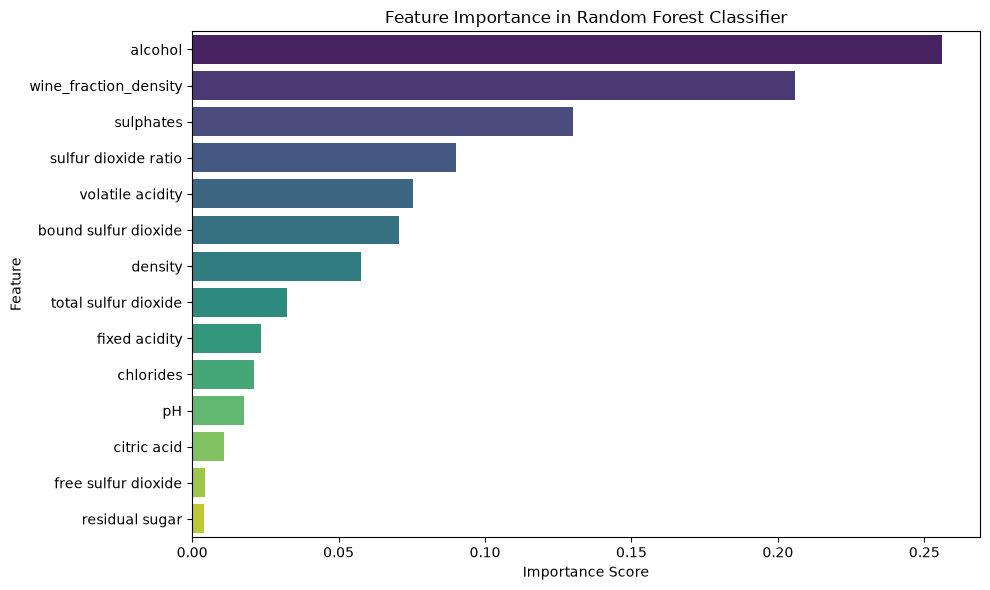

In [10]:
# Creating X and y
X = df_train.drop(['quality'],
                  axis=1)
y = df_train['quality']

# Splitting into training and test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.25,
                                                    random_state=42)

# Initializing a classifier
classifier = RandomForestClassifier(n_estimators=100,
                                    max_depth=5,
                                    random_state=42,
                                    min_impurity_decrease=0.01)
classifier.fit(X_train, y_train)

# Predictions
y_pred = classifier.predict(X_test)
y_pred_train = classifier.predict(X_train)

# Getting importance values
importances = classifier.feature_importances_
feature_names = X_train.columns

# Create a DataFrame and sort by importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance',
            y='Feature',
            data=feature_importance,
            palette='viridis'
)
plt.title('Feature Importance in Random Forest Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

#### Summary

We used Feature importance plot and heatmap to choose features as a starting point. We tried many combinations of features, including new features through feature engineering, and we found that *wine_fraction_density, sulphates, total sulfur dioxide, volatile acidity, and chlorides* had the best performance. 

### Features included in the model

In [11]:
features = [
    'wine_fraction_density',
    'sulphates',
    'total sulfur dioxide',
    'volatile acidity',
    'chlorides'
]

In [19]:
X = df_train[features]
y = df_train['quality']

### Modelling

In [13]:
depths = [4, 5, 6, 7]
num_estimators = [25, 100, 200, 300]
seeds = list(range(1, 51))

# Dictionary to store accuracies per hyperparameter combination
hyperparam_accuracies = {}

# Make dictionary where key is (num_estimators, depth), value holds train/test lists of accuracies
for n_est in num_estimators:
    for depth in depths:
        hyperparam_accuracies[(n_est, depth)] = {'train': [], 'test': []}
    
# Loop for every number of n_estimators
for n_est in num_estimators:
    # Loop for every max_depth value
    for depth in depths:
        # Loop for every seed_number
        for seed_number in seeds:
            X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.25,
            random_state=seed_number,
            stratify=y
            )

            # Instantiate Random forest classifier
            classifier = RandomForestClassifier(
                n_estimators=n_est,
                max_depth=depth,
                random_state=42,
                min_impurity_decrease=0.011,
                criterion='entropy',
                bootstrap=True,
                max_features='sqrt',
                min_samples_leaf=1,
                min_samples_split=10,
                
            )
            # Fit classifier
            classifier.fit(X_train, y_train)
            
            # Make predictions
            y_pred = classifier.predict(X_test)
            y_pred_train = classifier.predict(X_train)

            # Evaluate on test and train set
            accuracy_test = accuracy_score(y_test, y_pred)
            accuracy_train = accuracy_score(y_train, y_pred_train)
            
            # Store by hyperparameter combination
            hyperparam_accuracies[(n_est, depth)]['train'].append(accuracy_train)
            hyperparam_accuracies[(n_est, depth)]['test'].append(accuracy_test)

# Print mean accuracy table with 95% CI on mean test accuracy
print("\nMean Accuracy Table (Grouped by Hyperparameters):")
print(f"{'n_estimators':<12} | {'max_depth':<10} | {'Mean Train Accuracy (%)':<24} | {'Mean Test Accuracy (%)':<24} | {'95% CI Lower':<18} | {'95% CI Upper':<18}")
print("-" * 110)

# 95% confidence interval
z_score = 1.96

# Loop through every (n_est, depth) combination
for (n_est, depth) in hyperparam_accuracies.keys():
    train_accs = hyperparam_accuracies[(n_est, depth)]['train']
    test_accs = hyperparam_accuracies[(n_est, depth)]['test']
    
    # Calculate mean and standard deviation
    mean_train = np.mean(train_accs) * 100
    mean_test = np.mean(test_accs) * 100
    std_test = np.std(test_accs) * 100  # Sample standard deviation
    n = len(test_accs)
    
    # Calculate 95% confidence interval
    se = std_test / np.sqrt(n)
    margin_of_error = z_score * se
    ci_lower = mean_test - margin_of_error
    ci_upper = mean_test + margin_of_error
    
    print(f"{n_est:<12} | {depth:<10} | {mean_train:<24.2f} | {mean_test:<24.2f} | {ci_lower:<18.2f} | {ci_upper:<18.2f}")


Mean Accuracy Table (Grouped by Hyperparameters):
n_estimators | max_depth  | Mean Train Accuracy (%)  | Mean Test Accuracy (%)   | 95% CI Lower       | 95% CI Upper      
--------------------------------------------------------------------------------------------------------------
25           | 4          | 79.07                    | 75.28                    | 74.44              | 76.12             
25           | 5          | 79.85                    | 75.56                    | 74.66              | 76.46             
25           | 6          | 80.57                    | 75.53                    | 74.64              | 76.41             
25           | 7          | 80.86                    | 75.31                    | 74.38              | 76.23             
100          | 4          | 79.25                    | 75.68                    | 74.82              | 76.55             
100          | 5          | 80.13                    | 75.76                    | 74.92              | 76.

Calculate and plot accuracy means

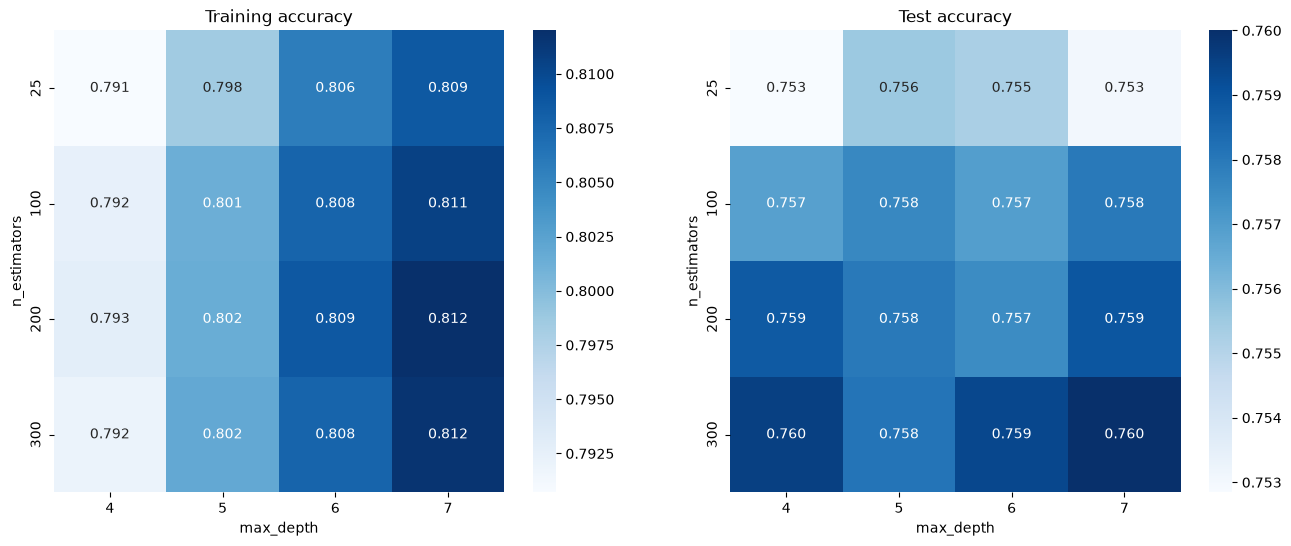

In [14]:
# Convert accuracies to pandas DataFrame
accuracies = pd.DataFrame(hyperparam_accuracies).transpose()

# Calculate mean
accuracies['train_mean'] = [np.mean(sublist) for sublist in accuracies['train']]
accuracies['test_mean'] = [np.mean(sublist) for sublist in accuracies['test']]

# Reshape flat list into 2d matrix
train_matrix = np.array(accuracies['train_mean']).reshape(len(num_estimators), len(depths))
test_matrix = np.array(accuracies['test_mean']).reshape(len(num_estimators), len(depths))

# Create figure with both heatmaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Create heatmap for train accuracies
sns.heatmap(
    train_matrix,
    xticklabels=depths,
    yticklabels=num_estimators,
    ax=ax1,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
ax1.set_title("Training accuracy")
ax1.set_xlabel("max_depth")
ax1.set_ylabel("n_estimators")

# Create heatmap for test accuracies
sns.heatmap(
    test_matrix,
    xticklabels=depths,
    yticklabels=num_estimators,
    ax=ax2,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
ax2.set_title("Test accuracy")
ax2.set_xlabel("max_depth")
ax2.set_ylabel("n_estimators")
plt.show()

#### Summary

Through several runs we found that one of the new features we created did improve the performance of our model. We decided to go with these features:
- wine_fraction_density
- Total sulfur dioxide
- Sulphates
- Volatile acidity
- Chlorides

Through grid searches, accuracy heatmaps and many runs we found the following hyperparameters:

- n_estimators: 300
- max_depth: 4
- criterion: 'entropy'
- min_impurity_decrease: 0.011
- max_features: 'sqrt'
- min_samples_leaf: 1
- min_samples_split: 10


We chose n_estimators=100 and max_depth=5 because these combinations were a good balance between training/test accuracy.
min_impurity_decrease was chosen at 0.011 because we wanted to avoid overfitting. Criterion = 'entropy' showed a slight increase in test accuracy, max features='sqrt', and min_samples_leaf, min_samples_split was found to give stable results at 1, and 10 respecitvely.

### Final evaluation

In [20]:
classifier = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    random_state=42,
    min_impurity_decrease=0.011,
    criterion='entropy',
    n_jobs=-1,
    bootstrap=True,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=10
)

X_train = X
y_train = y

classifier.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.011
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samp

### Kaggle submission

In [21]:
# Read data
df_test = pd.read_csv("test.csv")
df_test['wine_fraction_density'] =  df_test['density'] - df_test['alcohol']*0.789/100

X_test = df_test[features]

# Make predictions
y_final = classifier.predict(X_test)

# Create submission file
y_test = pd.DataFrame(y_final, columns=['quality'])
y_test.index.name = "Id"
y_test[['quality']].to_csv("submission.csv")